# Buyer Segmentation & Investment Profiling - Parcl
**Author:** Samarth Gairola

This notebook walks through the full analysis. The heavy computation (resampling tests) lives in `run_pipeline.py`; this notebook re-runs the cleaning and feature steps live and presents the saved results.

**Research question:** do distinct, reliable buyer segments exist in Parcl's client base, and how can they guide marketing?

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from src import data, features
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
FIG, RES = ROOT/"reports"/"figures", ROOT/"results"
show = lambda f: display(Image(filename=str(FIG/f)))

## 1. Data cleaning (Step 1 of the brief)
Three mixed date-of-birth formats, prices stored as text, PII columns. All checks below must pass.

In [2]:
raw_c, raw_p = data.load_raw()
print(raw_c.shape, raw_p.shape)
print(raw_c["date_of_birth"].head(3).tolist(), raw_p["sale_price"].head(2).tolist())
clients, log_c = data.clean_clients(raw_c)
props, log_p = data.clean_properties(raw_p)
print(log_c); print(log_p)
data.validate(clients, props)

(2000, 12) (10000, 9)
['05-11-1968', '11/26/1962', '04-07-1959'] ['$300,385.62', '$208,930.81']
{'rows_in': 2000, 'exact_duplicates_removed': 0, 'duplicate_ids_removed': 0, 'missing_before_imputation': {}, 'rows_out': 2000}
{'rows_in': 10000, 'duplicate_listings_removed': 0, 'sold': 7305, 'available': 2695, 'rows_out': 10000}


{'client_ids_unique': True,
 'dob_all_parsed': True,
 'age_in_range_18_100': True,
 'satisfaction_1_to_5': True,
 'prices_positive': True,
 'sold_units_have_buyer': True,
 'available_units_have_no_buyer': True,
 'all_buyers_exist_in_clients': True,
 'region_nested_in_country': True}

## 2. Feature engineering
The brief lists only client fields. Joining the property table adds purchase behaviour: units, spend, a **premium index** (price vs comparable units in the same tower/month/category), office share, tower concentration (**Herfindahl index**) and recency.

In [3]:
df = features.build_client_features(clients, props)
df[["age","satisfaction_score","units_bought","total_spend","premium_index","office_share","tower_hhi","recency_months"]].describe().round(3)

,age,satisfaction_score,units_bought,total_spend,premium_index,office_share,tower_hhi,recency_months
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,55.599,3.029,3.652,1260375.480,1.001,0.149,0.287,5.996
std,17.350,1.414,0.840,347830.665,0.051,0.185,0.047,4.929
min,25.000,1.000,3.000,463611.950,0.820,0.000,0.125,0.000
25%,40.875,2.000,3.000,1025238.005,0.969,0.000,0.250,2.000
50%,56.200,3.000,4.000,1220893.165,1.001,0.000,0.250,5.000
75%,70.000,4.000,4.000,1441973.882,1.034,0.250,0.333,9.250
max,94.900,5.000,13.000,3653385.380,1.194,1.000,0.503,22.000


## 3. Exploratory data analysis

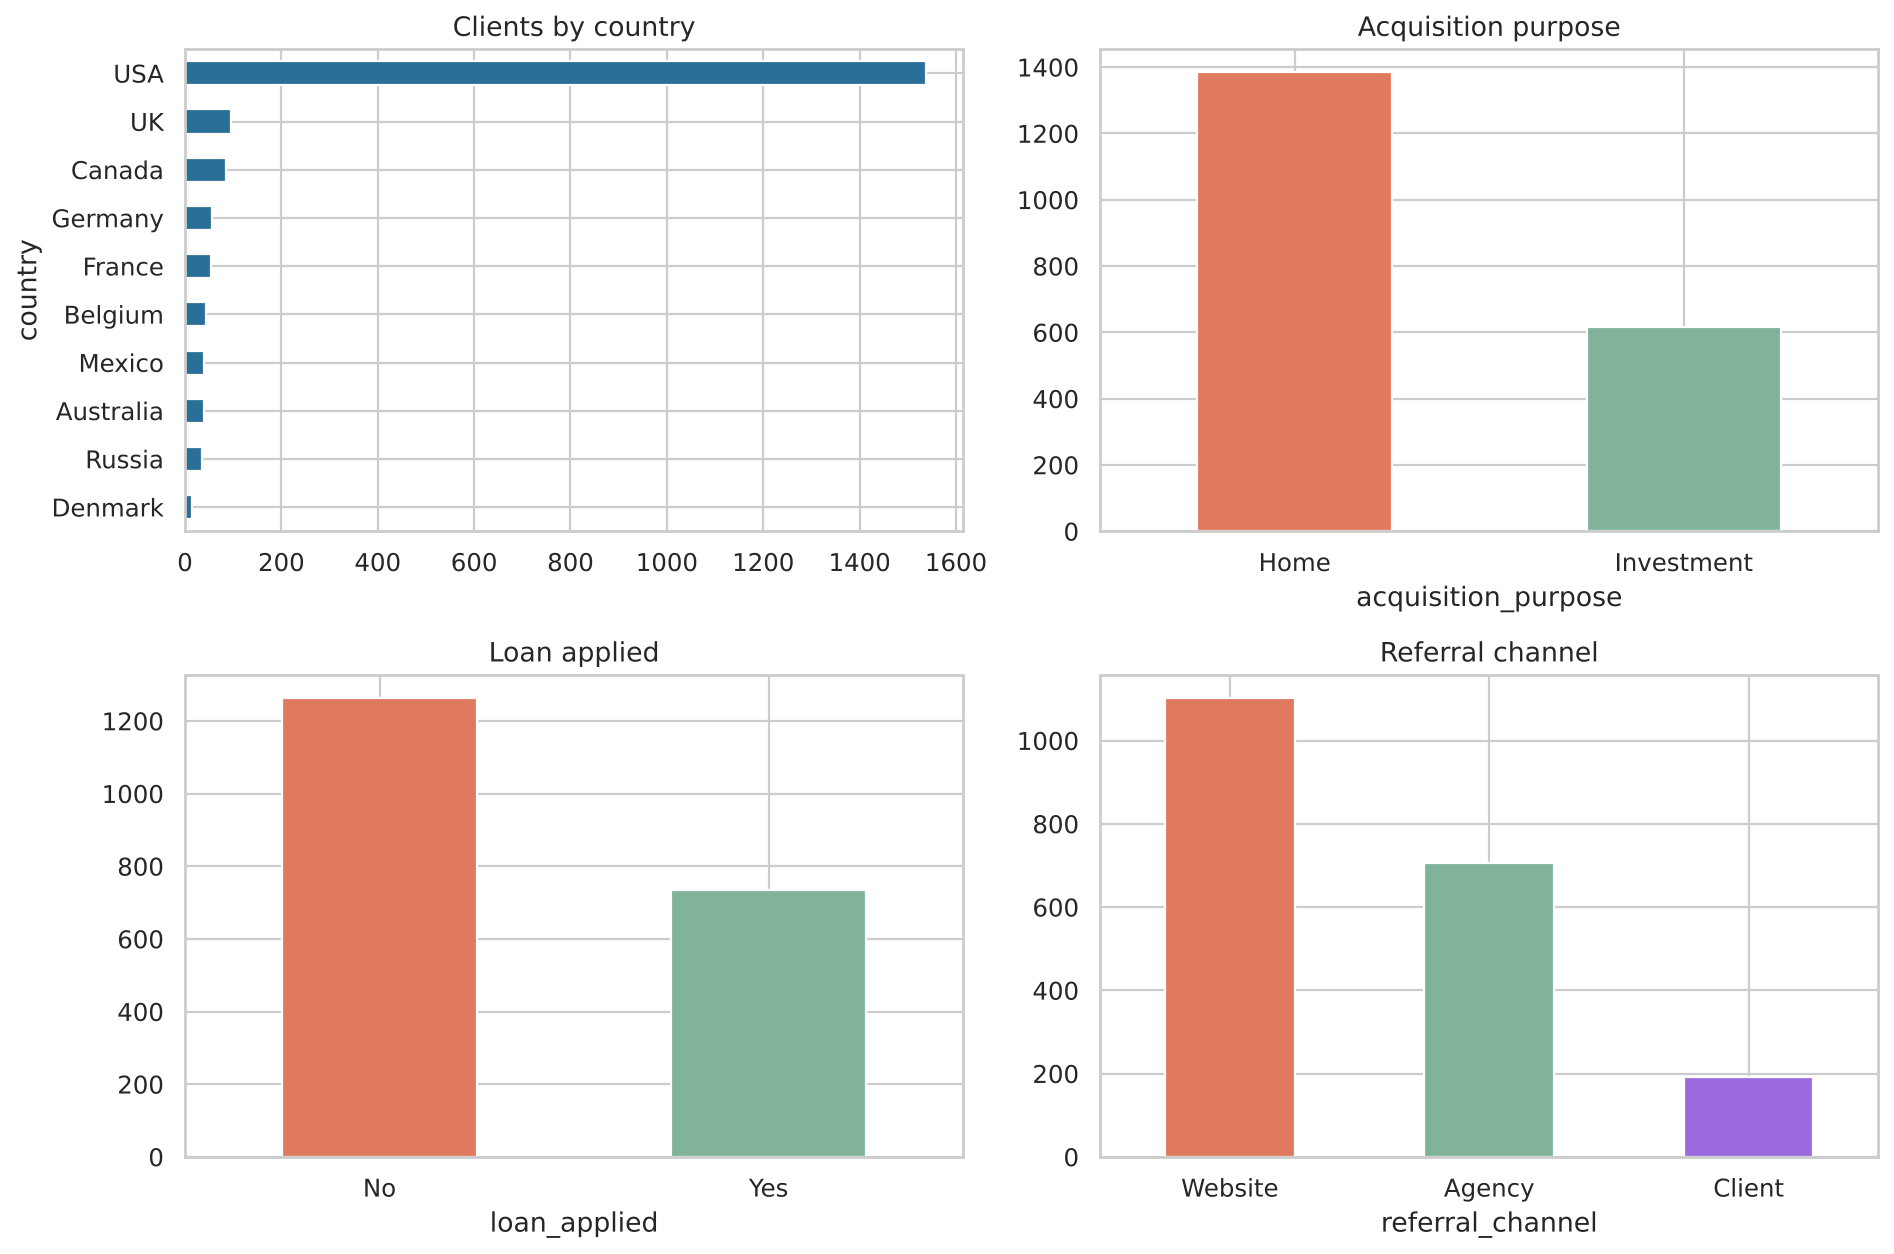

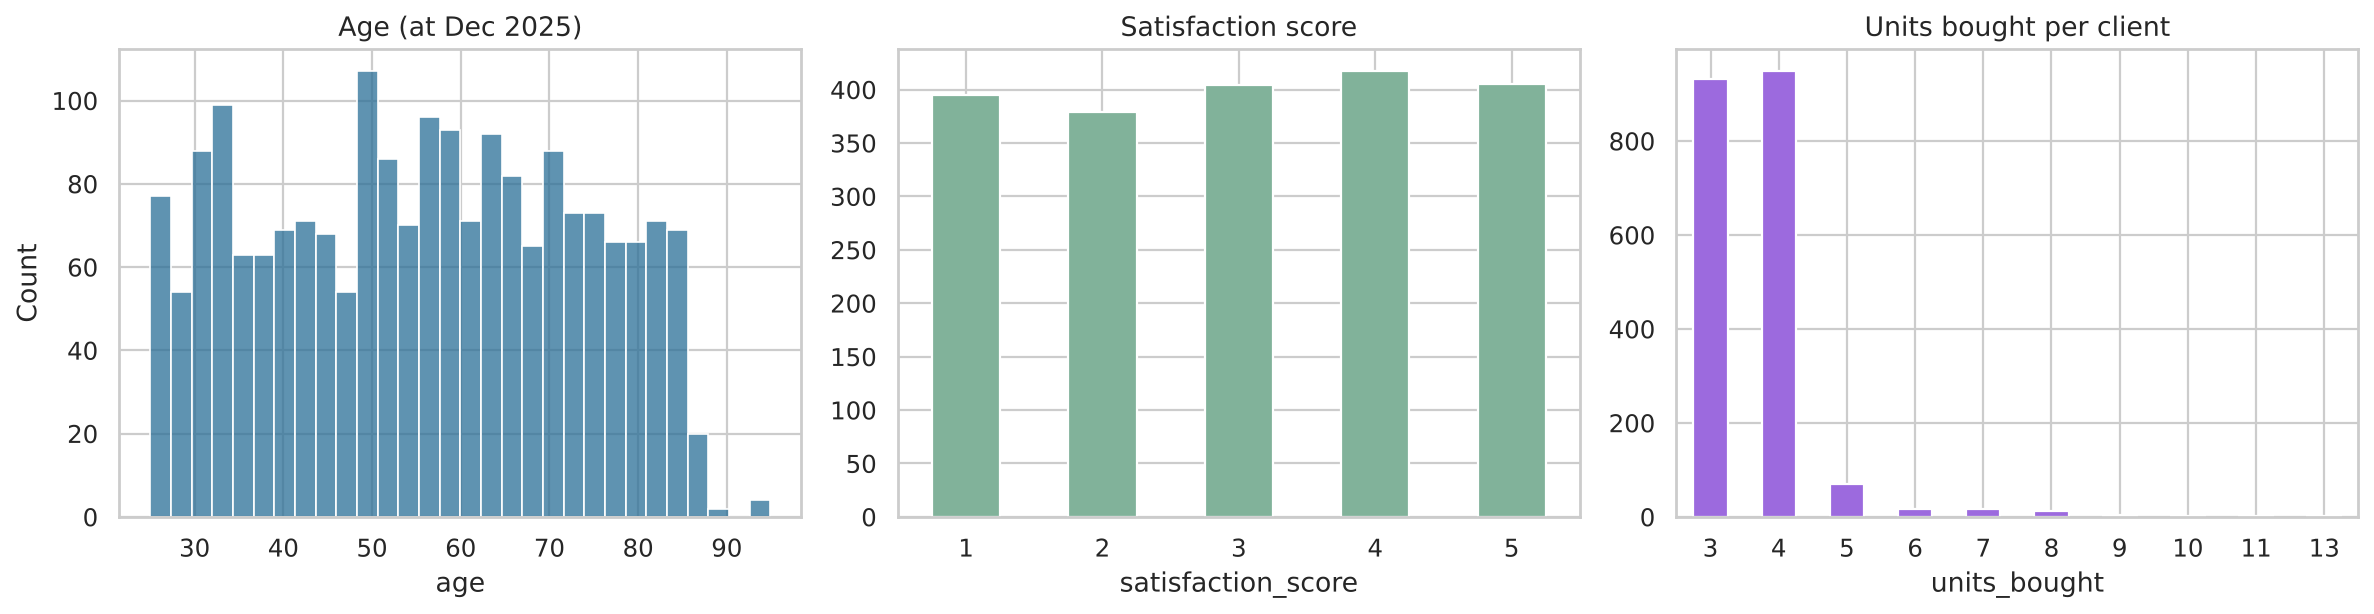

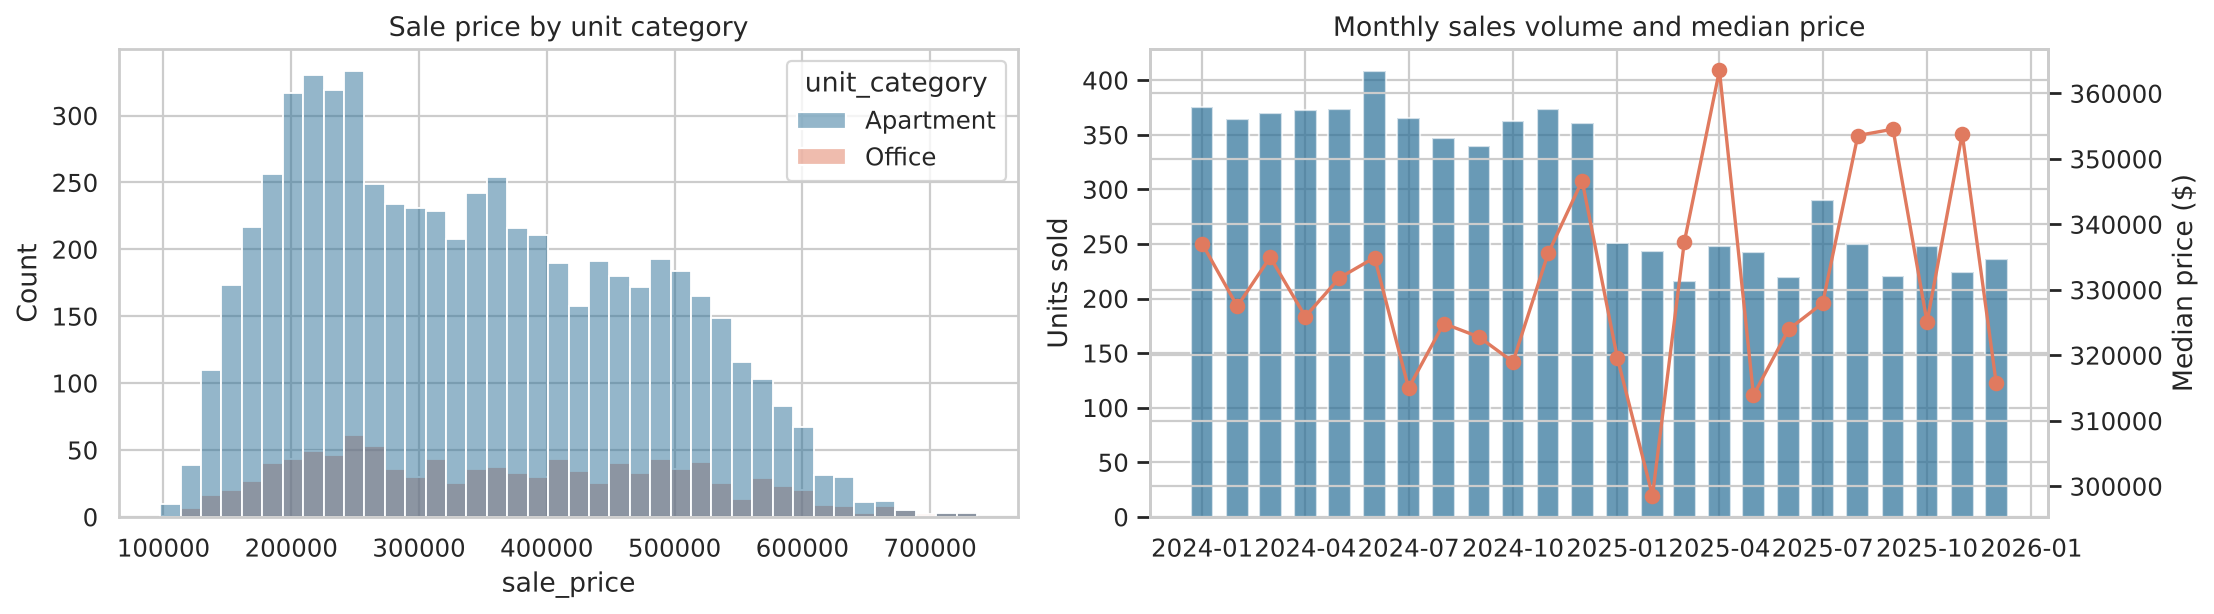

In [4]:
for f in ["fig01_categorical_overview.png","fig02_numeric_distributions.png","fig03_property_market.png"]: show(f)

### Independence audit
Cramér's V near 0 means two attributes are unrelated. Only one pair is significant after Benjamini-Hochberg correction: client type × age band.

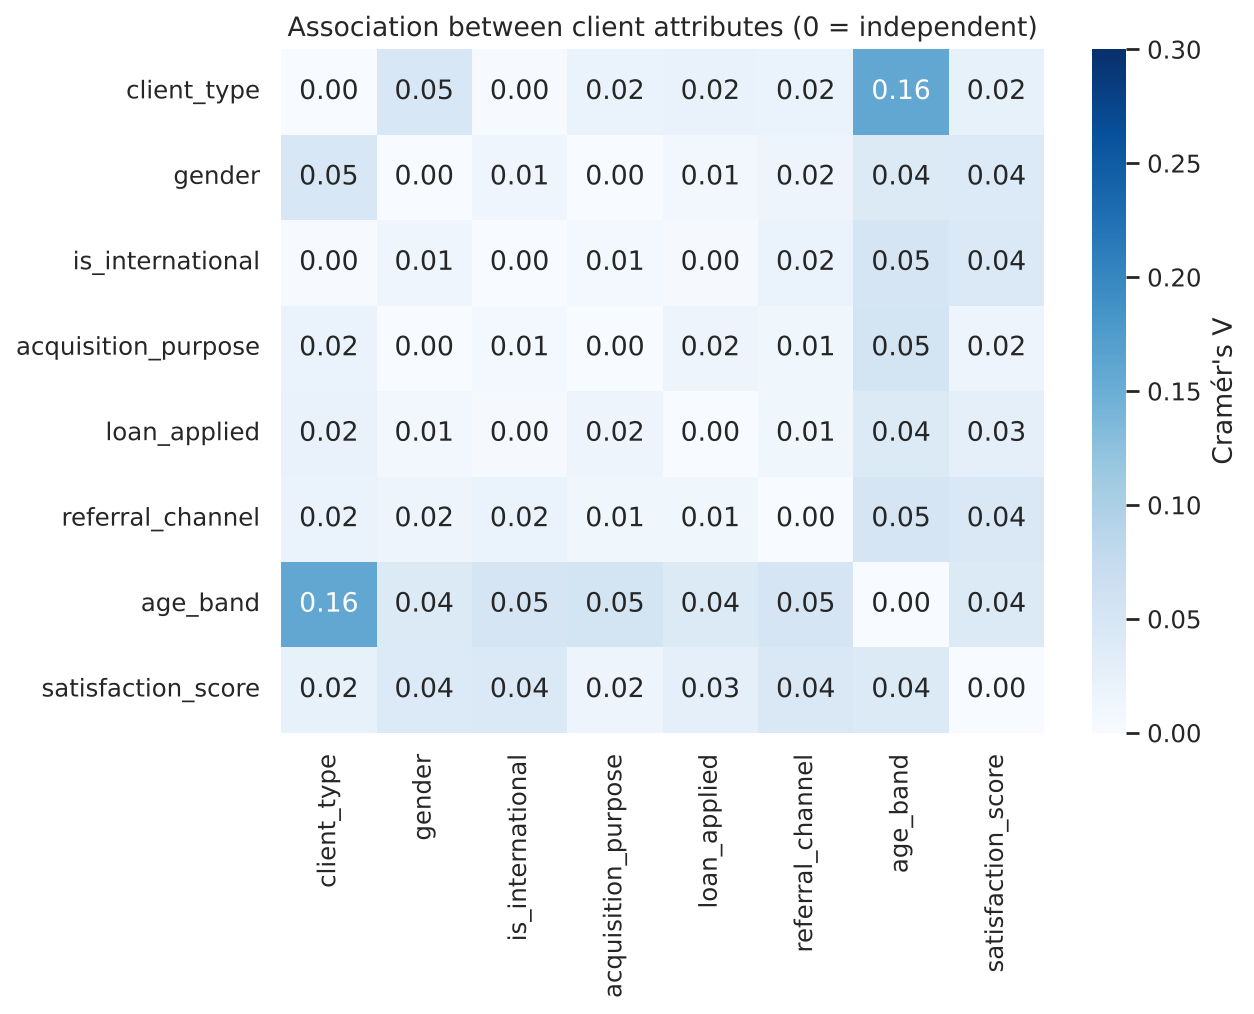

,var_a,var_b,cramers_v,p_value,p_bh
5,client_type,age_band,0.1591,0.0000,0.0000
20,acquisition_purpose,age_band,0.0548,0.1979,0.9760
25,referral_channel,age_band,0.0515,0.2239,0.9760
16,is_international,age_band,0.0511,0.2646,0.9760
0,client_type,gender,0.0470,0.0356,0.4991
26,referral_channel,satisfaction_score,0.0438,0.4675,0.9760


In [5]:
show("fig04_independence_heatmap.png")
pd.read_csv(RES/"independence_matrix.csv").sort_values("cramers_v", ascending=False).head(6).round(4)

### Pre-registered hypotheses (BH-adjusted)

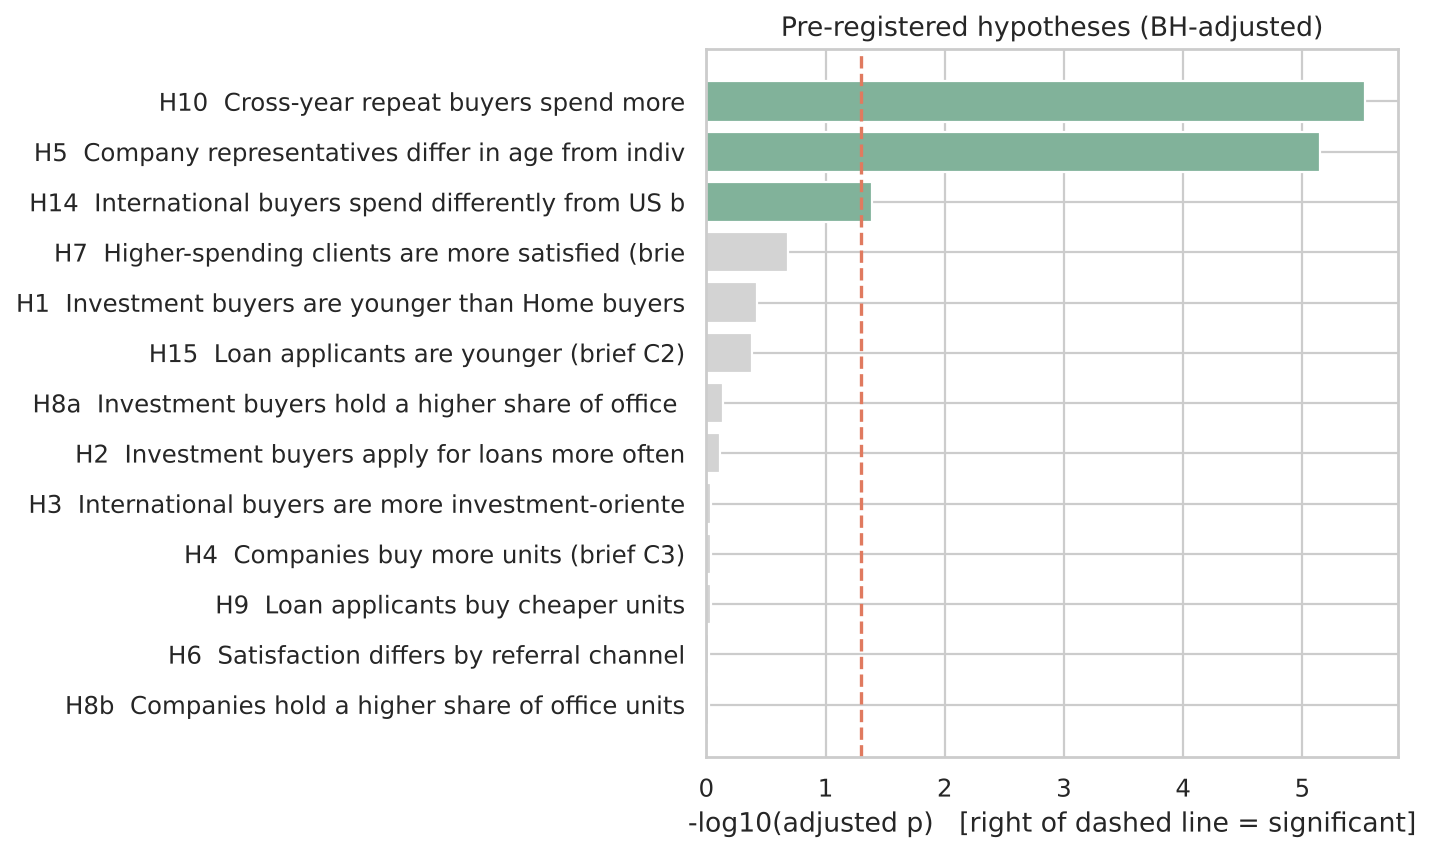

,id,hypothesis,evidence,p_bh,result
0,H1,Investment buyers are younger than Home buyers,54.80 vs 55.95 (n=615 vs 1385),0.3729,Not supported
1,H2,Investment buyers apply for loans more often,38.0% vs 36.2% (n=615 vs 1385),0.7648,Not supported
2,H3,International buyers are more investment-oriented,31.4% vs 30.6% (n=462 vs 1538),0.9212,Not supported
3,H4,Companies buy more units (brief C3),3.70 vs 3.65 (n=103 vs 1897),0.9212,Not supported
4,H5,Company representatives differ in age from ind...,47.60 vs 56.03 (n=103 vs 1897),0.0000,Supported
5,H6,Satisfaction differs by referral channel,"{'Agency': 3.02, 'Client': 3.06, 'Website': 3.03}",0.9511,Not supported
6,H7,Higher-spending clients are more satisfied (br...,rho = 0.041,0.2077,Not supported
7,H8a,Investment buyers hold a higher share of offic...,0.16 vs 0.15 (n=615 vs 1385),0.7289,Not supported
8,H8b,Companies hold a higher share of office units,0.15 vs 0.15 (n=103 vs 1897),0.9511,Not supported
9,H9,Loan applicants buy cheaper units,346903.66 vs 347198.43 (n=736 vs 1264),0.9212,Not supported


In [6]:
show("fig15_hypotheses.png")
pd.read_csv(RES/"hypothesis_tests.csv")[["id","hypothesis","evidence","p_bh","result"]].round(4)

## 4. Encoding, scaling and clustering (Steps 2-5)
- Binary fields label-encoded 0/1; nominal referral channel one-hot (Website baseline).
- Region (57 levels) kept out of clustering: it is nested in country and would dominate distances. It is used for profiling and the geographic analysis instead.
- Numerics standardised (StandardScaler); MinMaxScaler compared in `results/kmeans_scan_minmax.csv`.
- Three feature sets compared: **brief** fields only, **behaviour** only, **primary** (both).

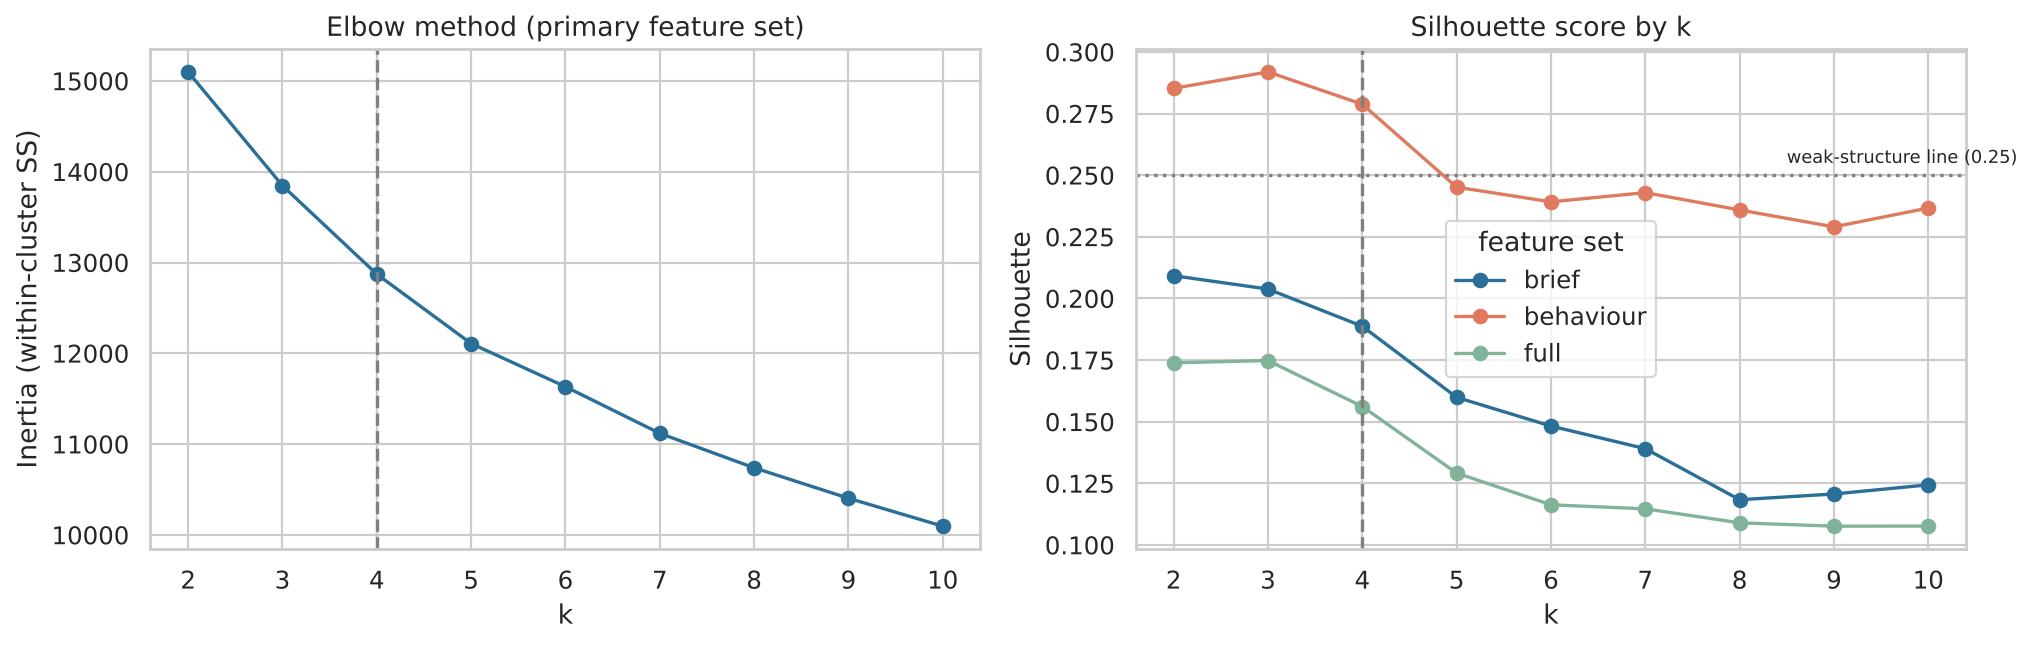

view,behaviour,brief,full
k,,,
2,0.285,0.209,0.174
3,0.292,0.204,0.175
4,0.279,0.189,0.156
5,0.245,0.160,0.129
6,0.239,0.148,0.116
7,0.243,0.139,0.115
8,0.236,0.118,0.109
9,0.229,0.121,0.108
10,0.237,0.124,0.108


In [7]:
scan = pd.read_csv(RES/"kmeans_scan.csv"); show("fig05_elbow_silhouette.png")
scan.pivot(index="k", columns="view", values="silhouette").round(3)

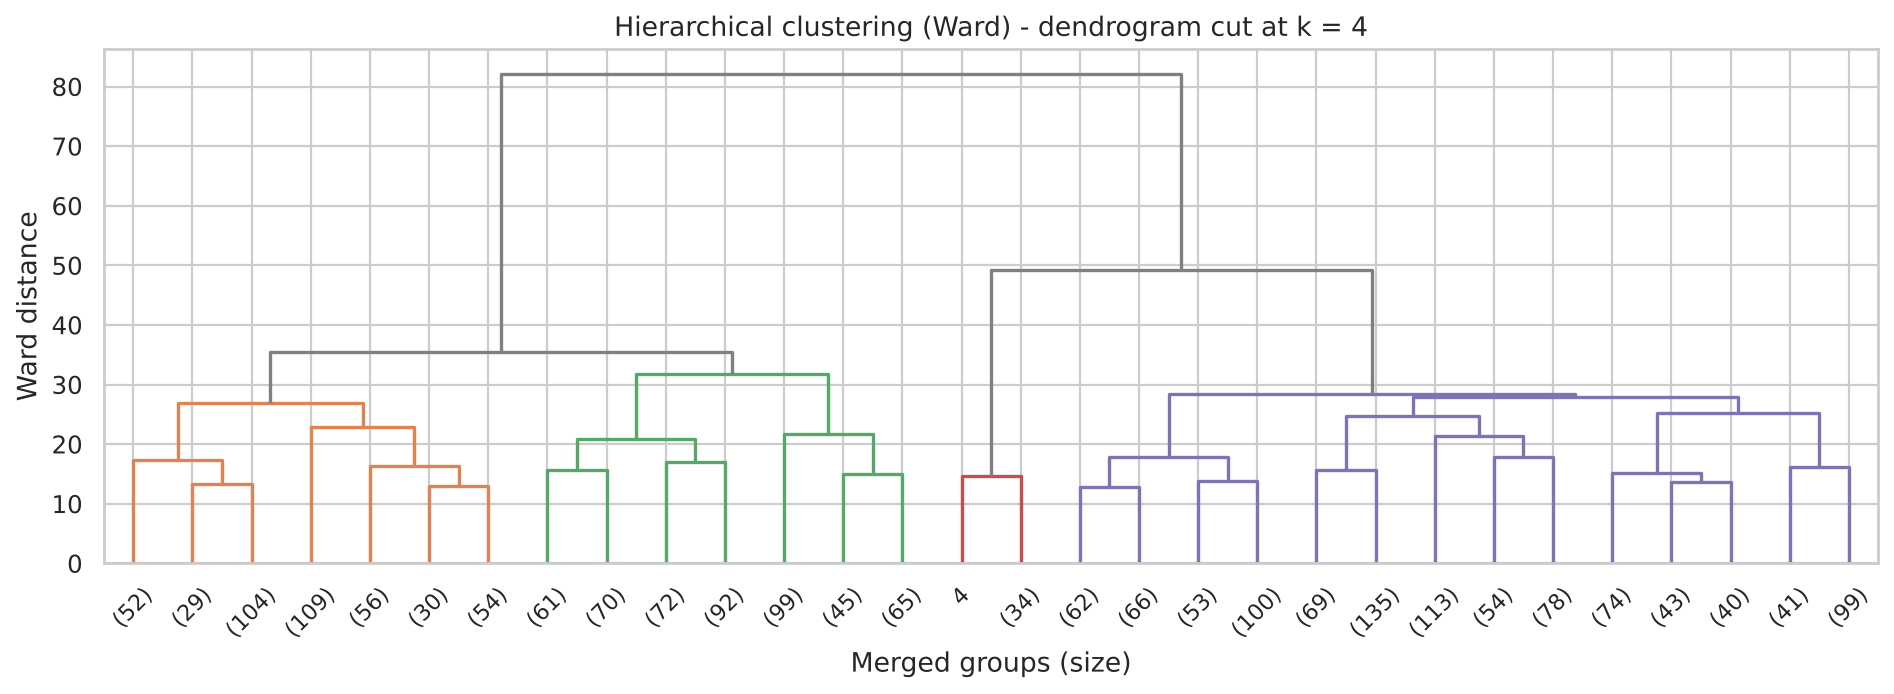

Agreement K-Means vs Hierarchical (ARI): 0.819
K-Prototypes vs brief K-Means (ARI): 0.679


In [8]:
show("fig06_dendrogram.png"); m = json.loads((RES/"metrics.json").read_text())
print("Agreement K-Means vs Hierarchical (ARI):", round(m["ari_kmeans_vs_hierarchical"],3))
print("K-Prototypes vs brief K-Means (ARI):", round(m["ari_kprototypes_vs_brief_kmeans"],3))

## 5. Are the segments real? Validation beyond Elbow and Silhouette
1. **Permutation null**: shuffle every column independently and re-cluster 200 times.
2. **Gap statistic**: compares against a uniform reference and is allowed to choose k = 1.
3. **Bootstrap stability**: mean Jaccard of each cluster across 100 resamples (≥ 0.75 = stable).

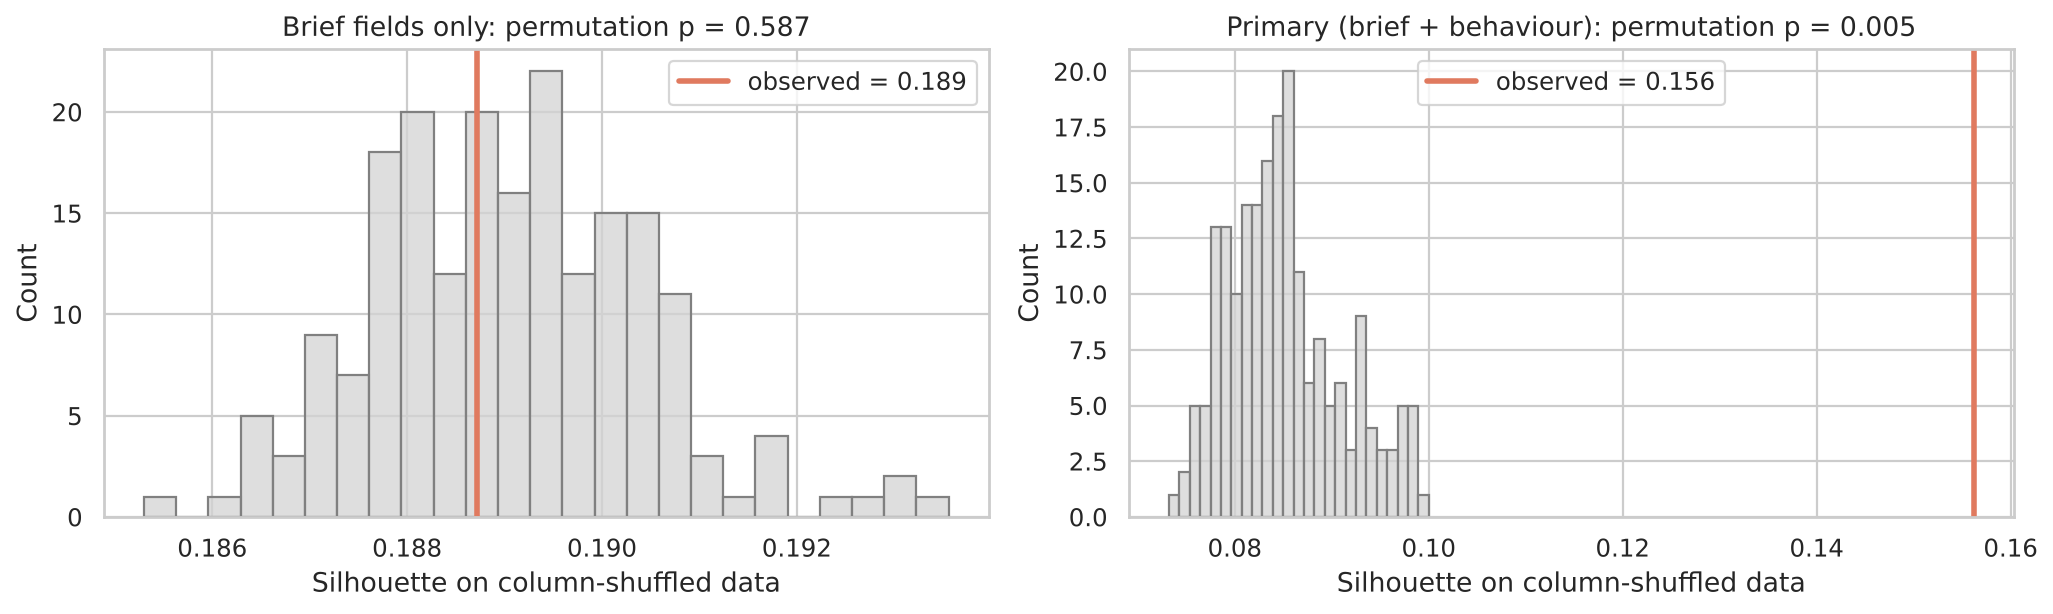

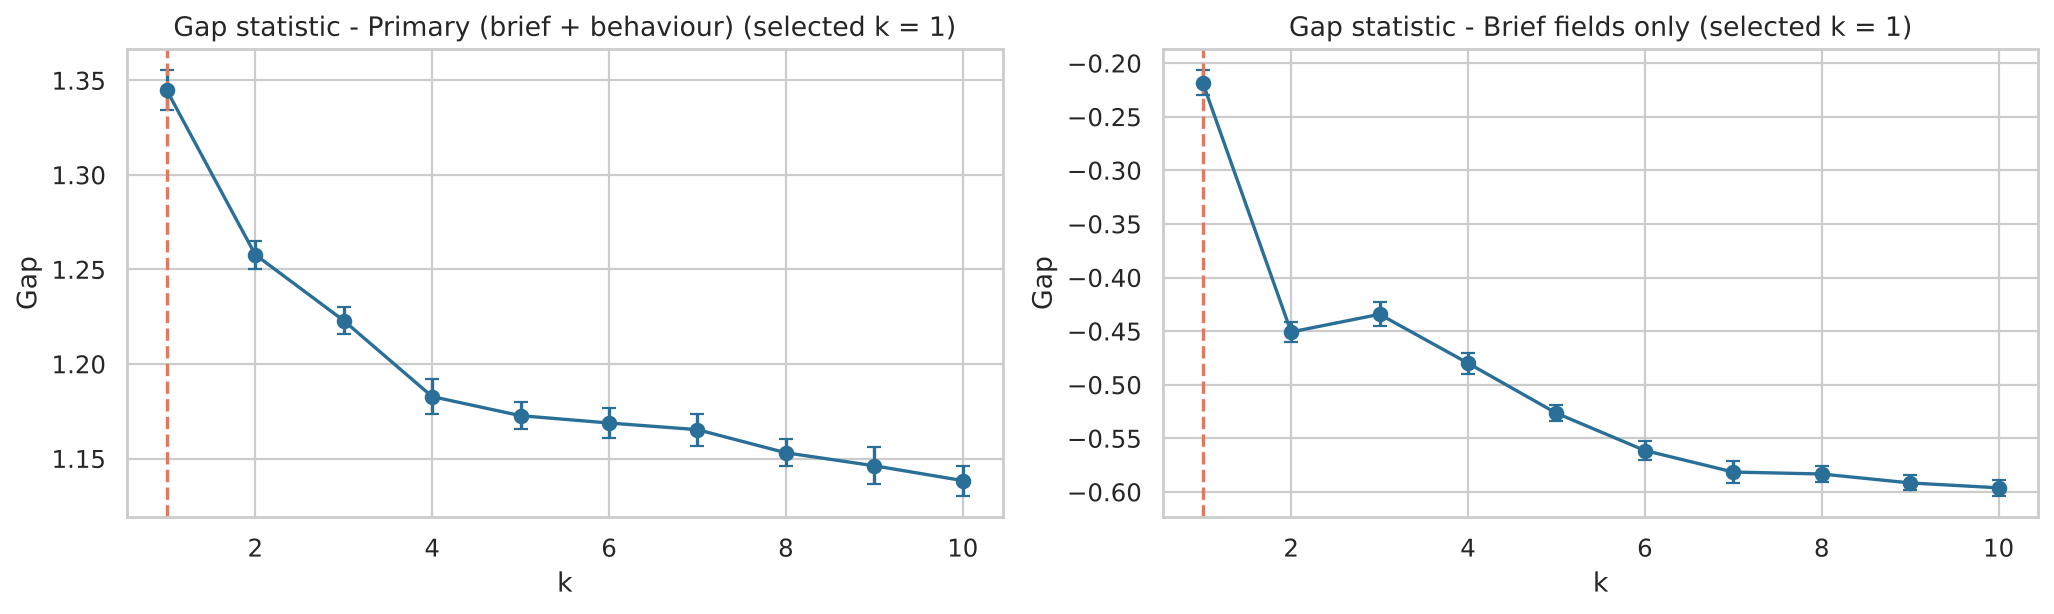

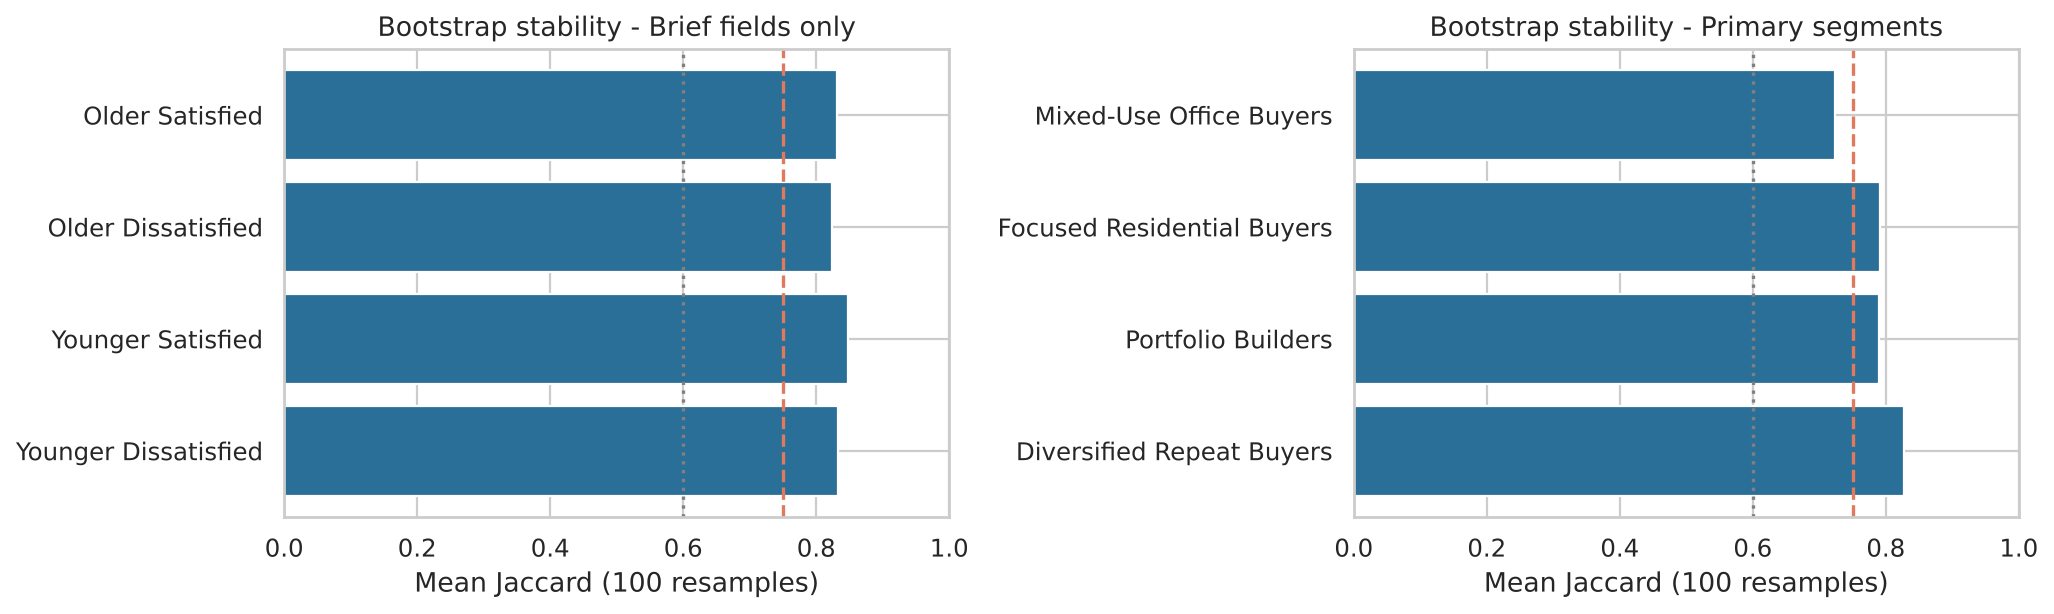

{'gap_selected_k_primary': 1, 'gap_selected_k_brief': 1}
primary: {'k': 4, 'observed': 0.1562, 'null_mean': 0.0851, 'null_sd': 0.0059, 'null_p95': 0.0971, 'p_value': 0.005}
brief:   {'k': 4, 'observed': 0.1887, 'null_mean': 0.1891, 'null_sd': 0.0014, 'null_p95': 0.1912, 'p_value': 0.5871}


In [9]:
show("fig08_permutation_null.png"); show("fig07_gap_statistic.png"); show("fig09_stability.png")
print({k: m[k] for k in ["gap_selected_k_primary","gap_selected_k_brief"]})
print("primary:", {k: round(v,4) for k,v in m["permutation_primary"].items()})
print("brief:  ", {k: round(v,4) for k,v in m["permutation_brief"].items()})

**Interpretation.** Brief-only clustering produces stable groups that are *no better than shuffled data*: it slices age × satisfaction into quadrants (figure below). Adding purchase behaviour yields segments that beat the null (p ≈ 0.005), are reproducible, and agree across algorithms. The gap statistic still prefers k = 1, so segments overlap and should be used as targeting tools rather than hard boundaries.

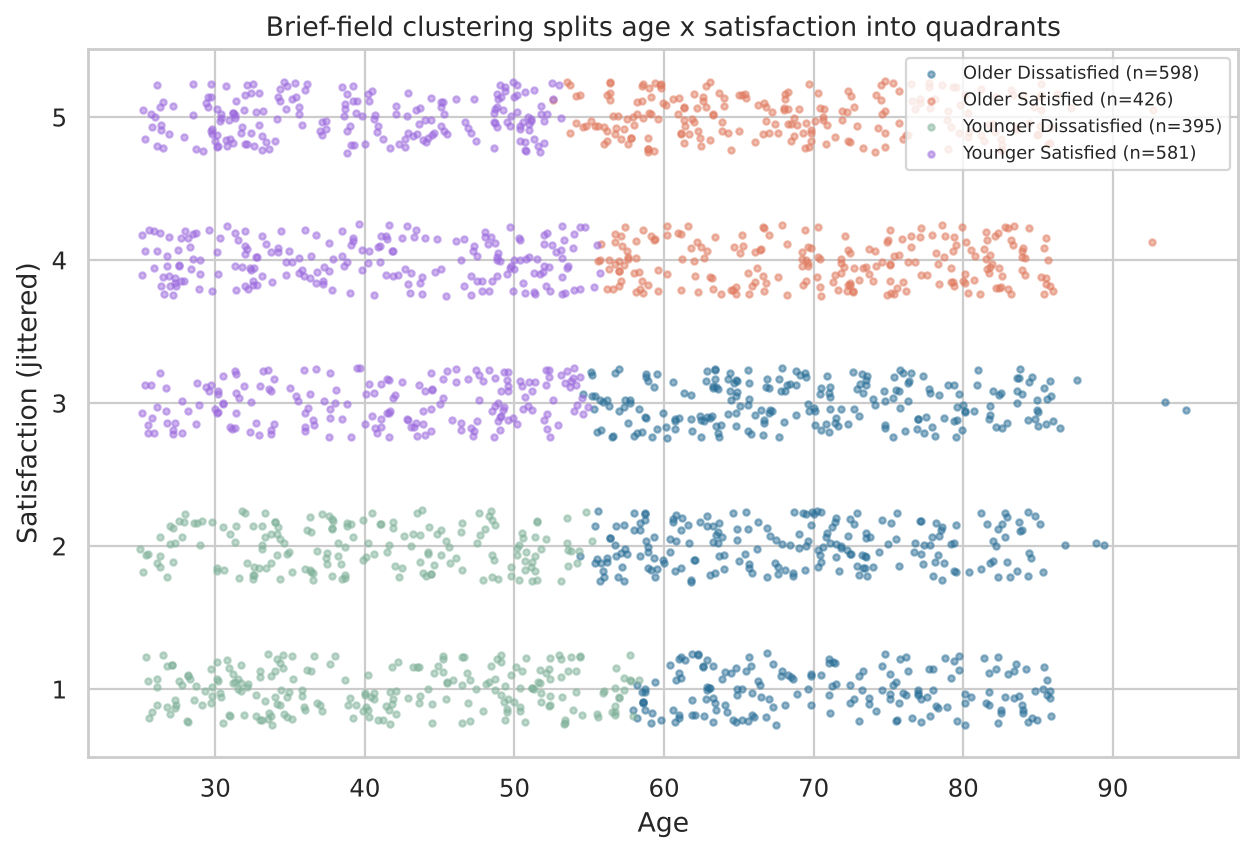

In [10]:
show("fig14_brief_quadrants.png")

## 6. Cluster interpretation (Step 6)

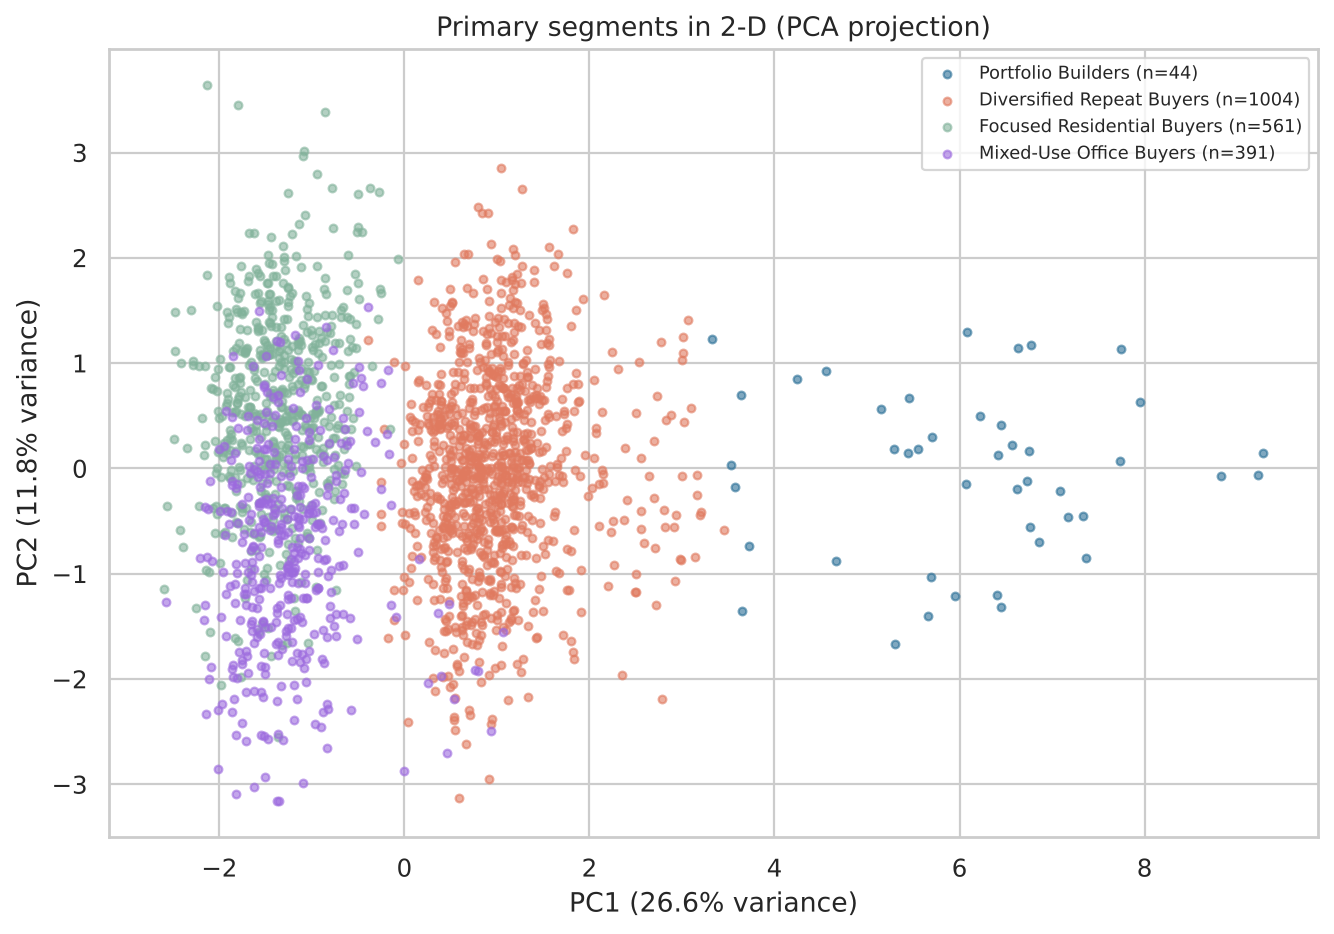

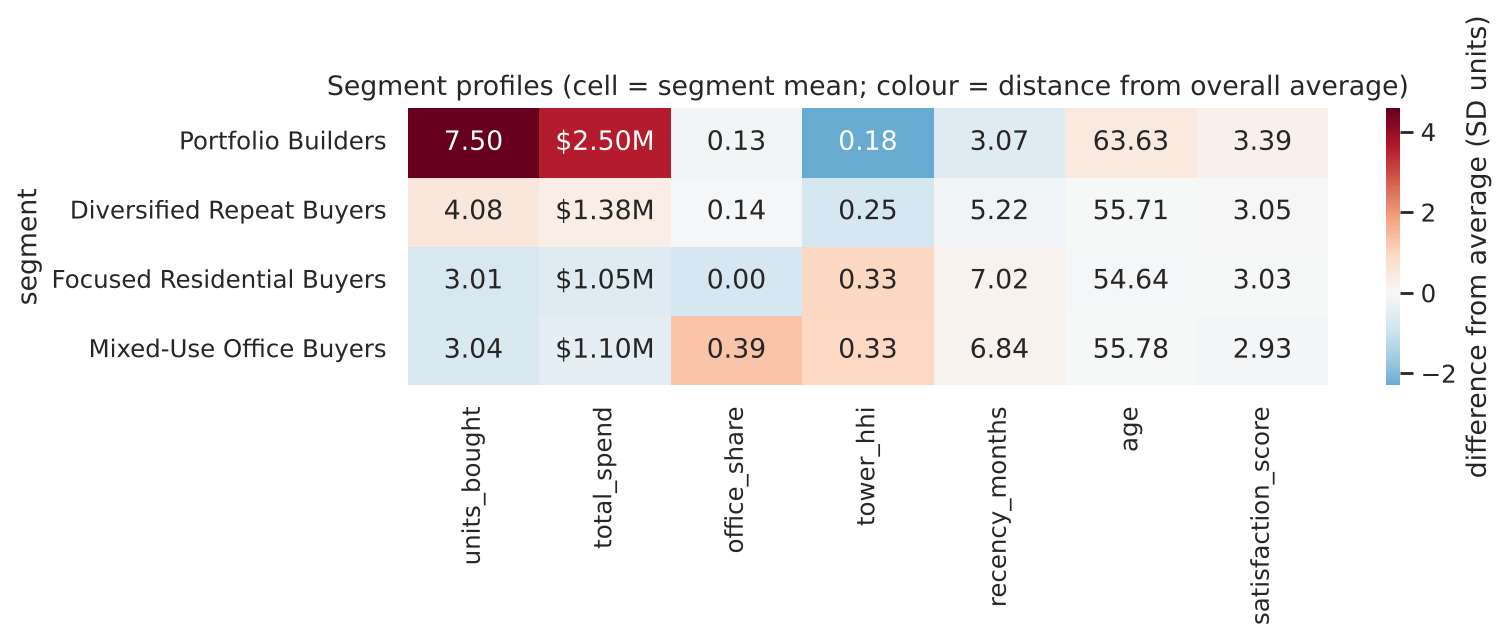

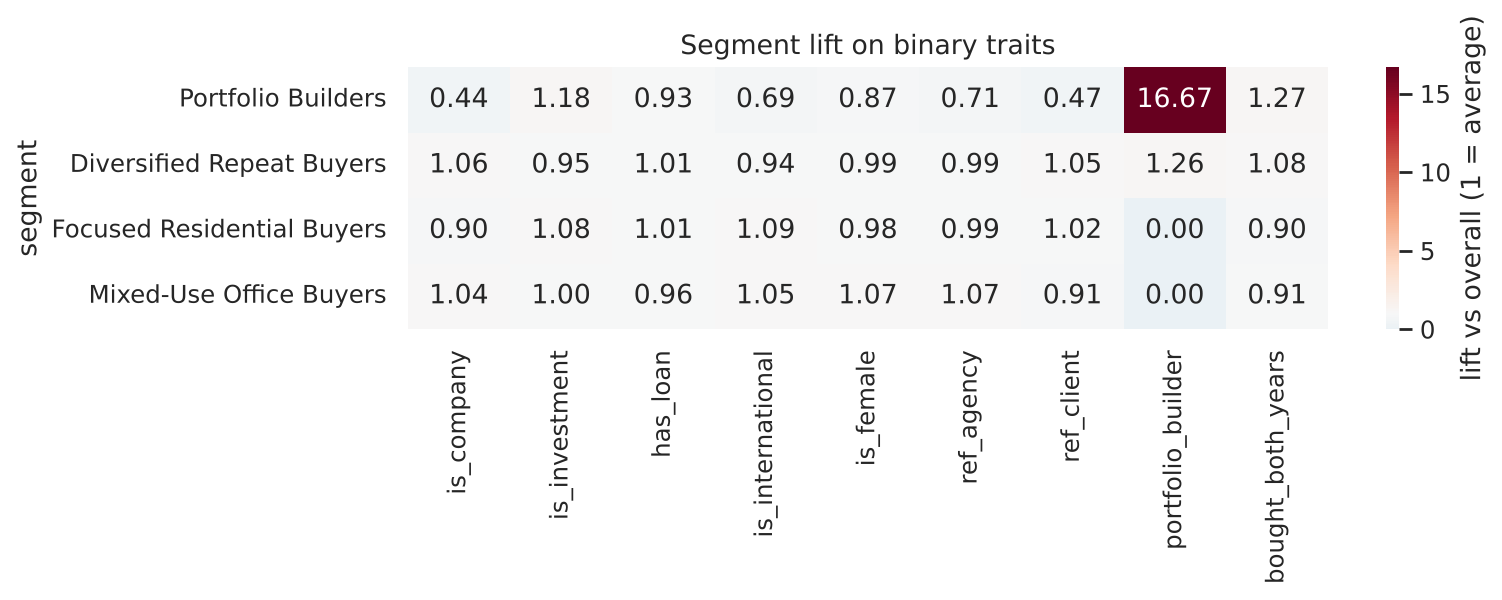

segment,Diversified Repeat Buyers,Focused Residential Buyers,Mixed-Use Office Buyers,Portfolio Builders,Overall
n,1004.00,561.00,391.00,44.00,2000.00
share_pct,50.20,28.05,19.55,2.20,100.00
age,55.71,54.64,55.78,63.63,55.60
satisfaction_score,3.05,3.03,2.93,3.39,3.03
units_bought,4.08,3.01,3.04,7.50,3.65
total_spend,1382278.19,1054222.80,1103447.80,2501740.46,1260375.48
avg_unit_price,339036.46,350599.23,363826.18,337388.68,347089.96
premium_index,1.00,1.00,1.00,1.00,1.00
office_share,0.14,0.00,0.39,0.13,0.15
tower_hhi,0.25,0.33,0.33,0.18,0.29


In [11]:
show("fig10_pca_segments.png"); show("fig11_segment_profile_heatmap.png"); show("fig12_segment_lift.png")
pd.read_csv(RES/"segment_profiles.csv", index_col=0).round(2).T

### Geographic distribution - location quotients
Borrowed from regional economics: LQ = segment share in a country ÷ segment share overall. 90% bootstrap intervals; countries with n < 30 flagged.

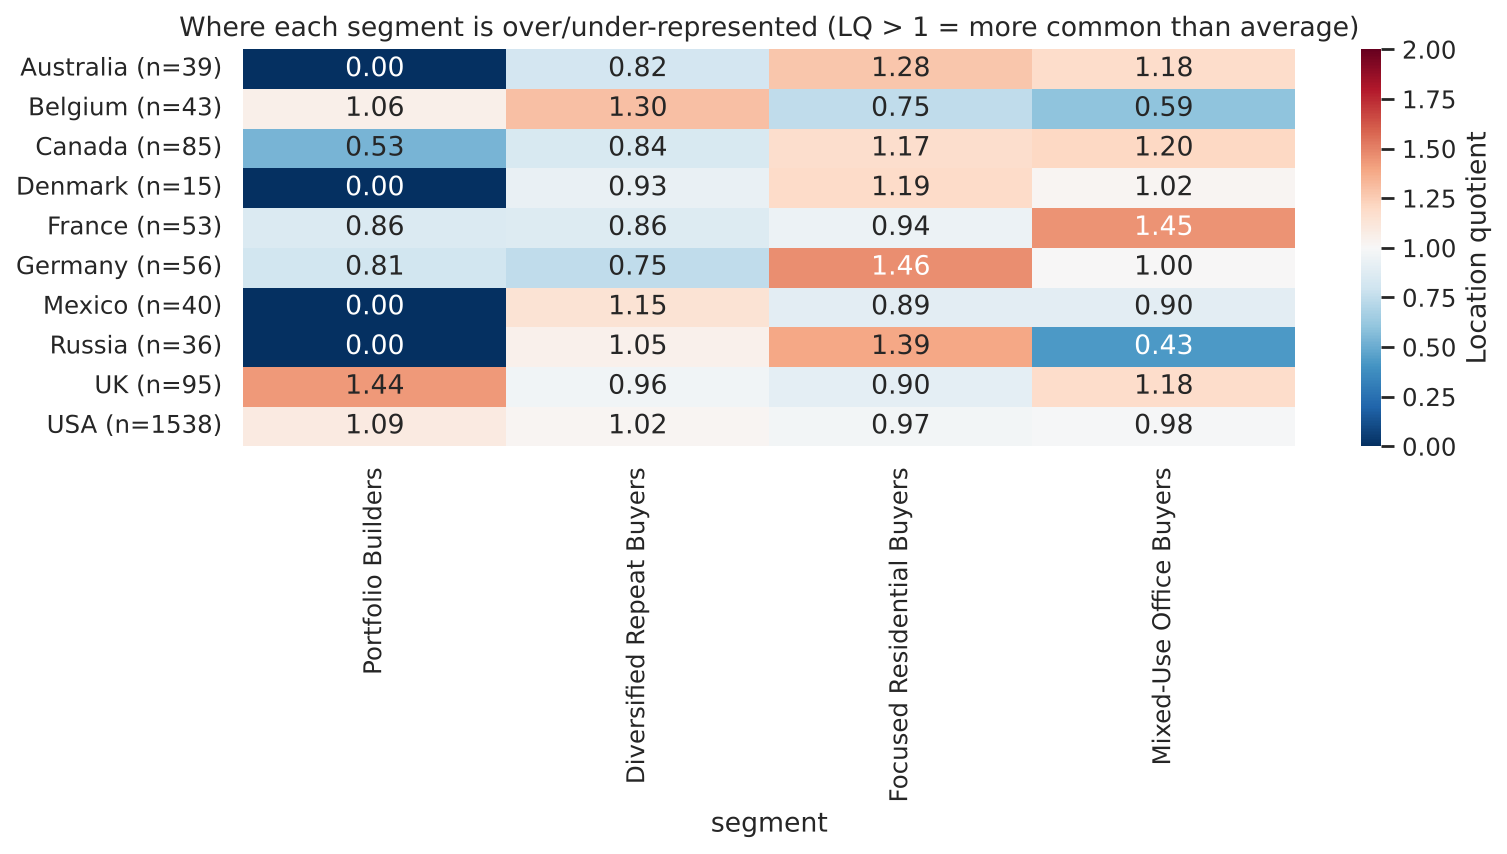

,country,segment,n_area,lq,ci_low,ci_high,reliable,significant
3,Australia,Portfolio Builders,39,0.00,0.00,0.00,True,True
4,Belgium,Diversified Repeat Buyers,43,1.30,1.07,1.53,True,True
6,Belgium,Mixed-Use Office Buyers,43,0.59,0.24,0.98,True,True
20,Germany,Diversified Repeat Buyers,56,0.75,0.50,0.95,True,True
21,Germany,Focused Residential Buyers,56,1.46,1.13,1.87,True,True
27,Mexico,Portfolio Builders,40,0.00,0.00,0.00,True,True
30,Russia,Mixed-Use Office Buyers,36,0.43,0.00,0.76,True,True
31,Russia,Portfolio Builders,36,0.00,0.00,0.00,True,True


In [12]:
show("fig13_location_quotient.png")
lq = pd.read_csv(RES/"lq_country.csv"); lq[lq.significant & lq.reliable].round(2)

### Decision usefulness
Do behaviour-only segments separate marketing attributes that were **not** used to build them, compared with random groupings of the same sizes?

In [13]:
pd.read_csv(RES/"decision_usefulness.csv").round(3)

,target,cramers_v,random_mean,random_p95,beats_random
0,acquisition_purpose,0.040,0.037,0.060,False
1,loan_applied,0.016,0.038,0.065,False
2,referral_channel,0.038,0.035,0.055,False
3,is_international,0.043,0.037,0.070,False
4,client_type,0.026,0.035,0.060,False
5,gender,0.037,0.036,0.062,False
6,age_band,0.070,0.044,0.060,True


## 7. Brief segments C1-C4 vs evidence
| Brief segment | Finding |
|---|---|
| C1 Global Investors | Not found: international buyers are not more investment-oriented and spend slightly less |
| C2 First-Time Buyers | Not found: loan applicants are not younger; first-time status unobservable |
| C3 Corporate Buyers | Not found as described: same units; representatives ~8 years younger |
| C4 Luxury Investors | Partial: Portfolio Builders spend most and are somewhat more satisfied |

See `reports/research_paper.pdf` for the full discussion and recommendations.